In [167]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

In [7]:
def F(x, r, N, xc):
    return r*x*(1 - 1/(1 + np.exp(xc - x))
                + x/((1 + np.exp(xc - x))*(N + x)))

def dF_dx(x, r, N, xc, h=1e-6):
    return (F(x+h, r, N, xc) - F(x-h, r, N, xc)) / (2*h)

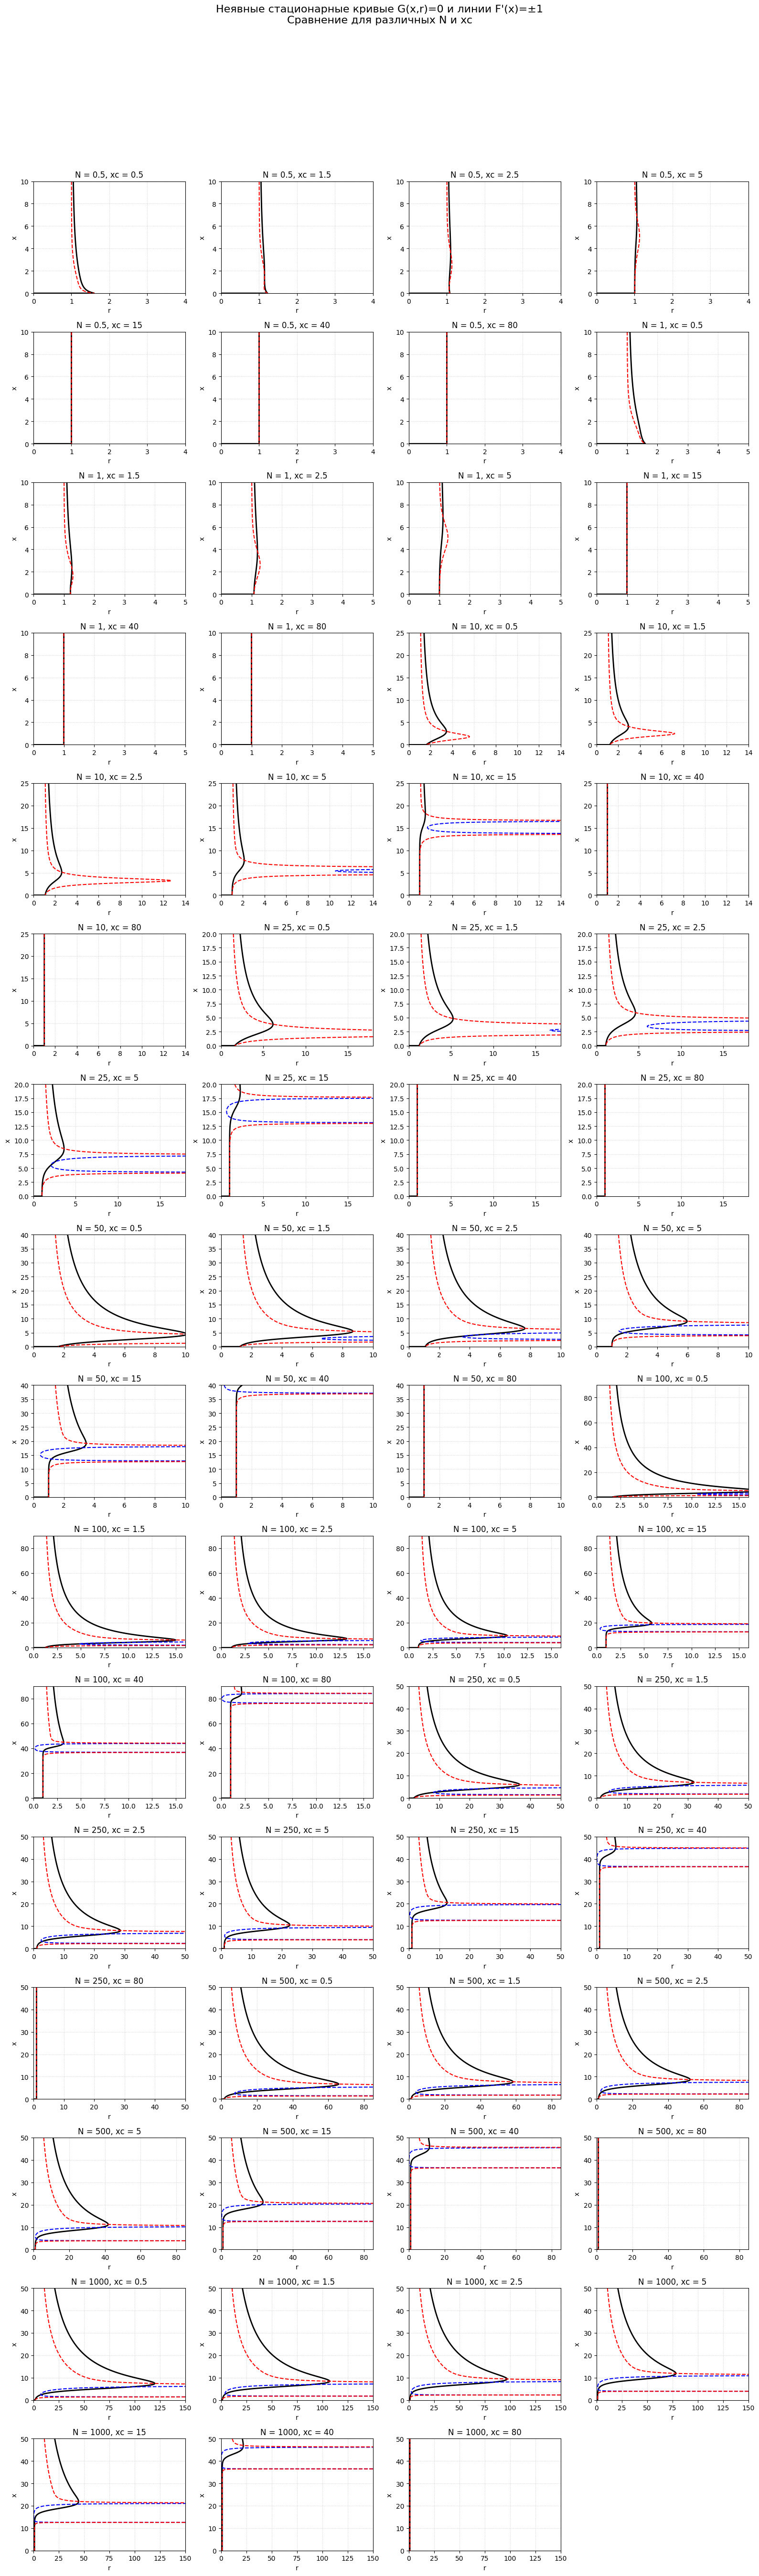

In [37]:
xc_values = [0.5, 1.5, 2.5, 5, 15, 40, 80]
N_values  = [0.5, 1, 10, 25, 50, 100, 250, 500, 1000]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 10, 25: 20, 0.5: 10, 10: 25, 50: 40, 100: 90, 250: 50, 500: 50, 1000: 50}
r_max_map = {1: 5, 25: 18, 0.5: 4, 10: 14, 50: 10, 100: 16, 250: 50, 500: 85, 1000: 150}
ncols = 4
nrows = int(np.ceil(len(param_sets) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 55))
axes = axes.flatten()

for ax, (N, xc) in zip(axes, param_sets):
    x_max = x_max_map.get(N, 50)
    r_max = r_max_map.get(N, 10)
    x = np.linspace(0, x_max, 500)
    r = np.linspace(0, r_max, 500)
    R, X = np.meshgrid(r, x)

    G = X - F(X, R, N, xc)
    dF = dF_dx(X, R, N, xc)
    ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
    ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
    ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')

    ax.set_title(f"N = {N}, xc = {xc}")
    ax.set_xlabel("r")
    ax.set_ylabel("x")
    ax.grid(True, linestyle=":", alpha=0.6)
for i in range(len(param_sets), len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Неявные стационарные кривые G(x,r)=0 и линии F'(x)=±1\n"
    "Сравнение для различных N и xc",
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# Для 80-ти везде слишком высоко поднялось, но в целом тенденция понятна. Увеличение $x_c$ поднимает все крючки (синий, красный и черный) выше и приближает к оси $y$ синий крючок.

In [208]:
def F(x, r, N, xc):
    return r*x*(1 - 1/(1 + np.exp(xc - x))
                + x/((1 + np.exp(xc - x))*(N + x)))

def dF_dx(x, r, N, xc, h=1e-6):
    return (F(x+h, r, N, xc) - F(x-h, r, N, xc)) / (2*h)

def plot_stability(param_sets, x_max_map, r_max_map, ncols, x_len, y_len):
    nrows = int(np.ceil(len(param_sets) / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(x_len, y_len))
    axes = axes.flatten()
    
    for ax, (N, xc) in zip(axes, param_sets):
        x_max = x_max_map.get(N, 50)
        r_max = r_max_map.get(N, 10)
        x = np.linspace(0, x_max, 500)
        r = np.linspace(0, r_max, 500)
        R, X = np.meshgrid(r, x)
    
        G = X - F(X, R, N, xc)
        dF = dF_dx(X, R, N, xc)
        
        stable = (dF > -1) & (dF < 1)
    
        # ax.contourf(
        #     R, X, stable,
        #     levels=[0.5, 1],
        #     colors=['#ccffe5'],
        #     alpha=0.7
        # )
        # 
        # ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
        # ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
        # ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')
        
        ax.contourf(
            R, X, stable,
            levels=[0.5, 1],
            colors=['#ccffe5'],
            alpha=0.8
        )

        # ===== КРИВЫЕ =====
        c_stationary = ax.contour(
            R, X, G,
            levels=[0],
            colors='black',
            linewidths=2
        )

        c_minus = ax.contour(
            R, X, dF,
            levels=[-1],
            colors='blue',
            linestyles='dashed'
        )

        c_plus = ax.contour(
            R, X, dF,
            levels=[1],
            colors='red',
            linestyles='dashed'
        )

        # ===== ПОДПИСИ НА ЛИНИЯХ =====
        mask = np.abs(G) < 0.01 * x_max
        i, j = np.argwhere(mask)[len(np.argwhere(mask)) // 2]
        
        ax.text(
            R[i, j], X[i, j], '1',
            fontsize=12,
            ha='center',
            va='center',
            bbox=dict(facecolor='white', edgecolor='none', pad=0.3)
        )
        ax.clabel(c_minus, fmt={-1: '2'}, fontsize=12)
        ax.clabel(c_plus, fmt={1: '3'}, fontsize=12)

        # ===== ПОДПИСЬ ВНУТРИ ЗЕЛЁНОЙ ОБЛАСТИ =====
        # выбираем точку, где stable == True
        idx = np.argwhere(stable)
        if idx.size > 0:
            i, j = idx[len(idx) // 2]
            ax.text(
                R[i, j], X[i, j], '4',
                fontsize=12,
                color='#ccffe5',
                ha='center',
                va='center',
                path_effects=[pe.withStroke(linewidth=2, foreground='black')]
            )
    
        ax.set_title(f"xc = {xc}, N = {N}")
        ax.set_xlabel("r")
        ax.set_ylabel("x")
        ax.grid(True, linestyle=":", alpha=0.6)
    for i in range(len(param_sets), len(axes)):
        axes[i].axis("off")
    
    # plt.suptitle(
    #     "Неявные стационарные кривые G(x,r)=0 и область |F'(x)| < 1\n"
    #     "Сравнение для различных N и xc",
    #     fontsize=16
    # )
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

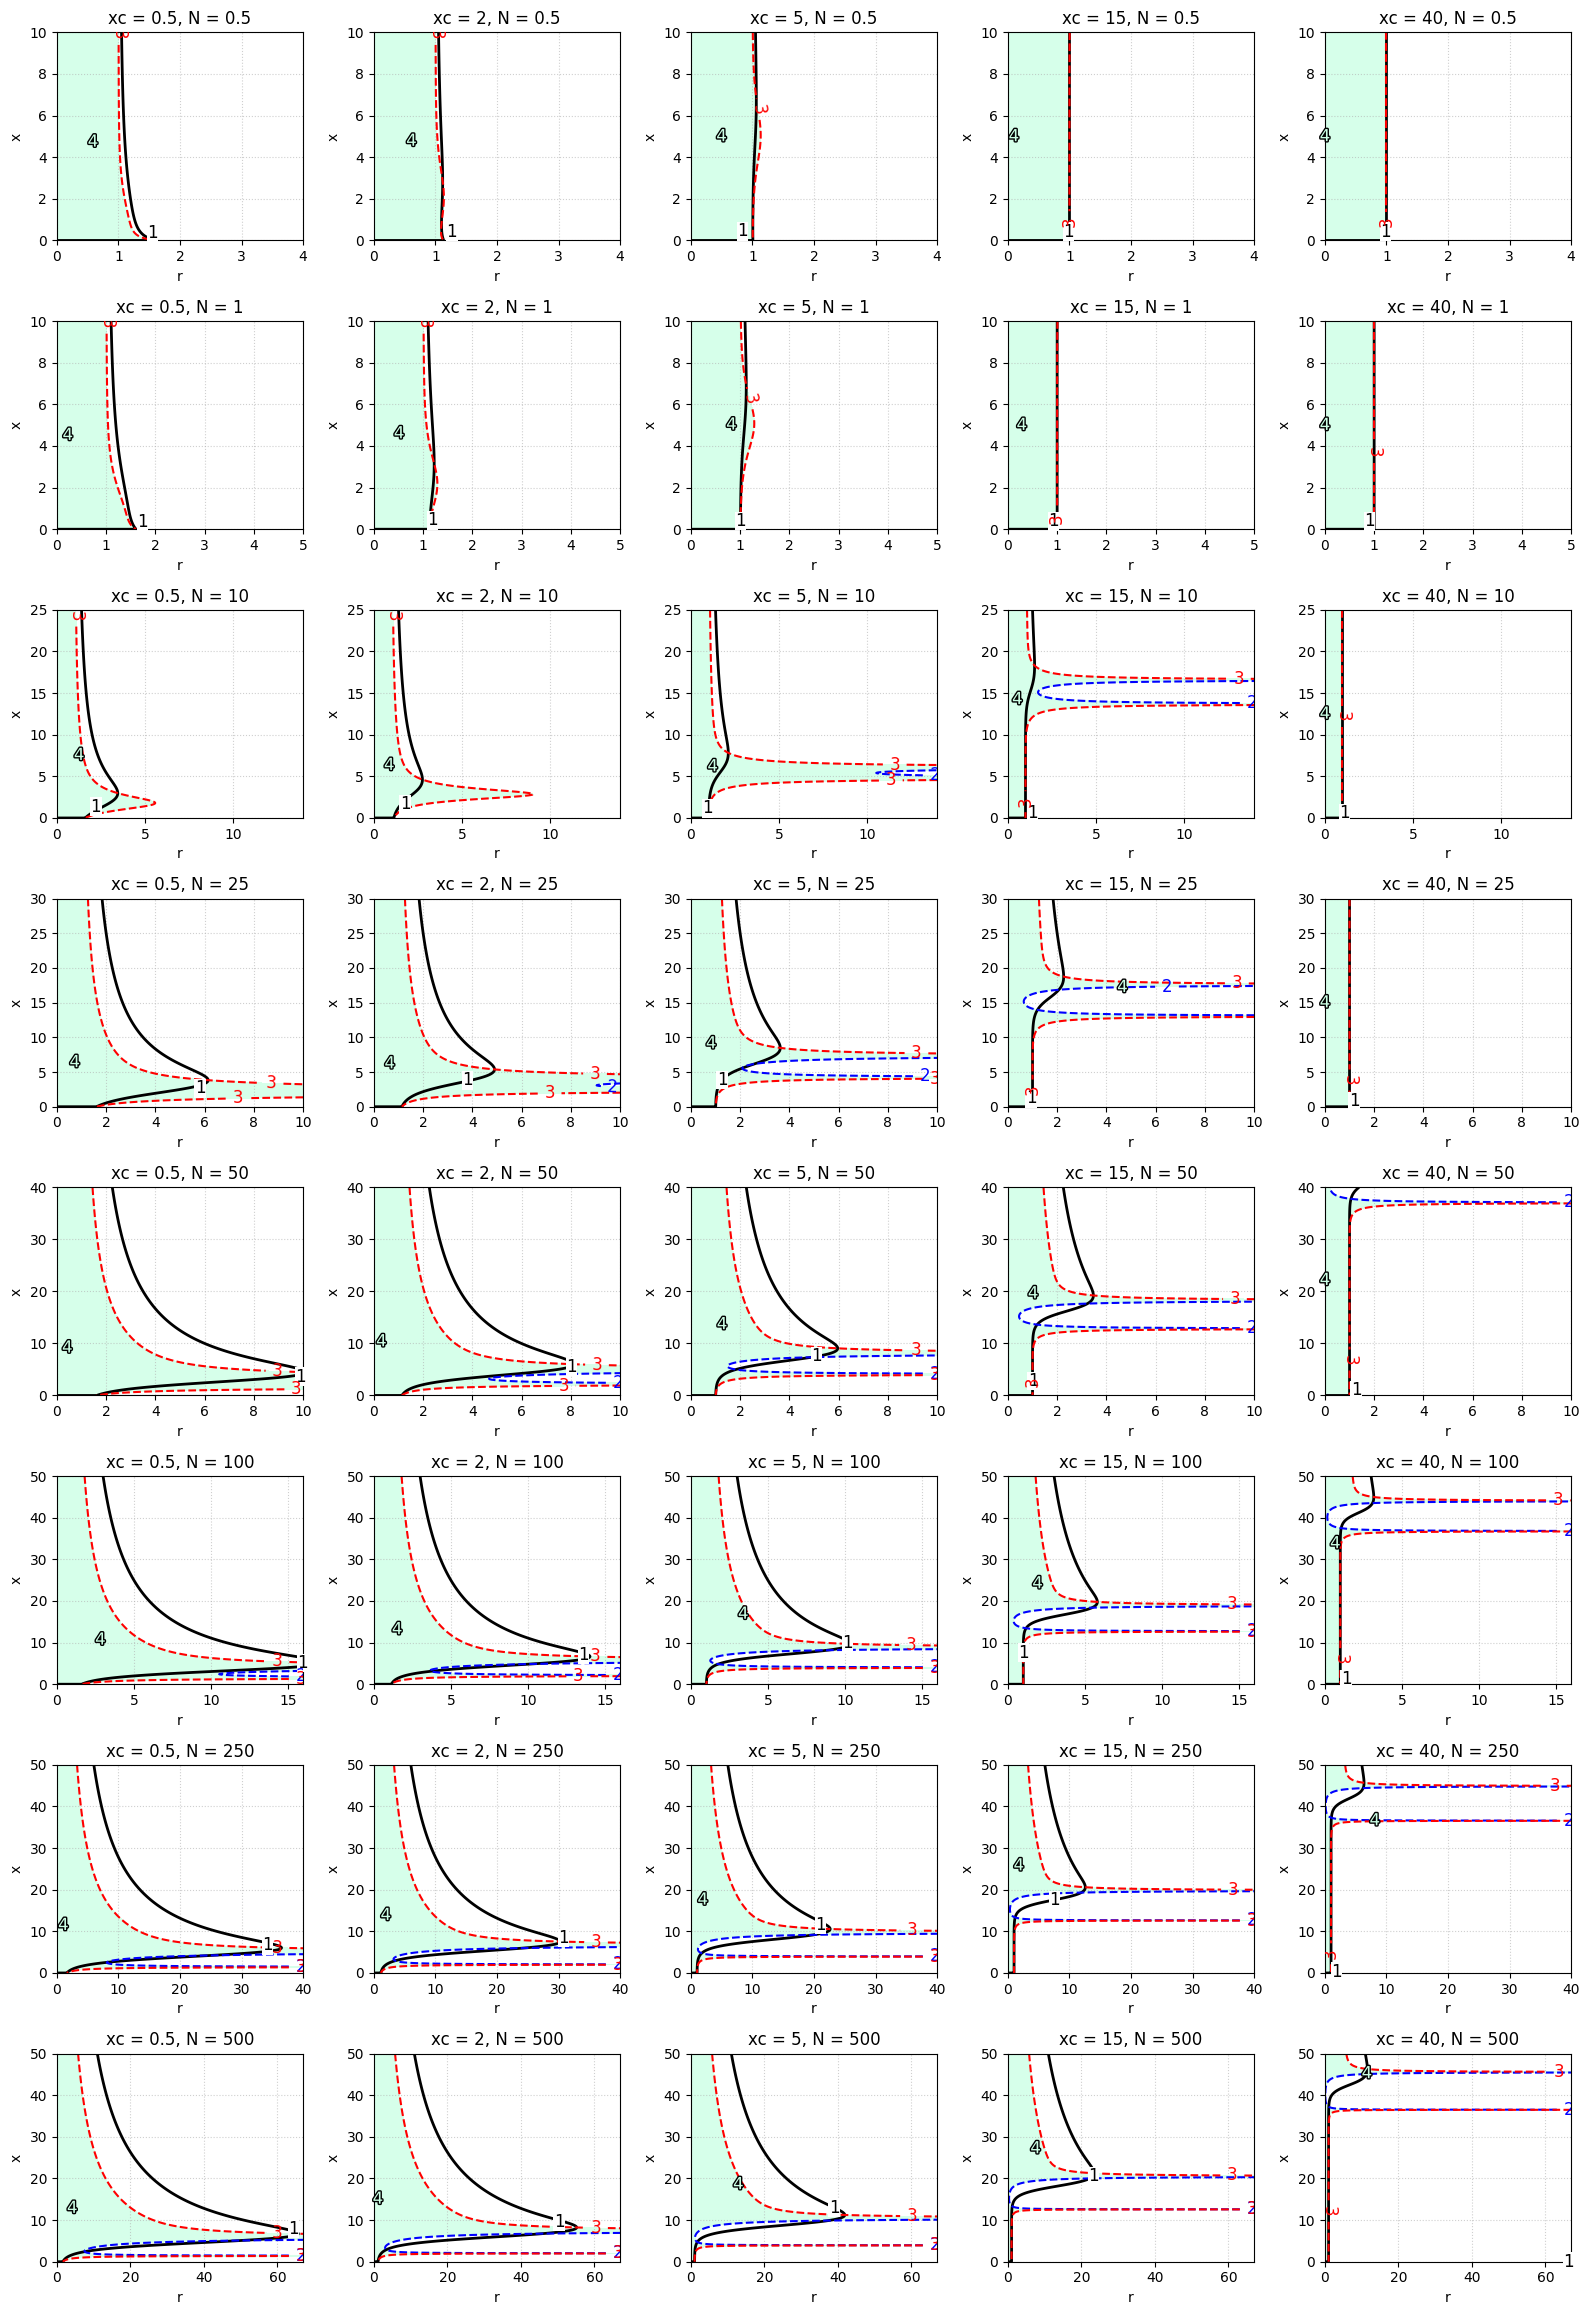

In [212]:
xc_values = [0.5, 2, 5, 15, 40]
N_values  = [0.5, 1, 10, 25, 50, 100, 250, 500]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]
x_max_map = {1: 10, 25: 30, 0.5: 10, 10: 25, 50: 40, 100: 50, 250: 50, 500: 50, 1000: 50}
r_max_map = {1: 5, 25: 10, 0.5: 4, 10: 14, 50: 10, 100: 16, 250: 40, 500: 67, 1000: 150}
ncols = 5

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 25)

In [205]:
def r_bifurcation_ax(ax, xc_val, N_val, x_start, r_max = 5):
    P = np.linspace(0, r_max, 1500)
    N0 = N_val
    xc = xc_val
    R = []
    X = []
    for r in P:
        x = x_start
        for n in range(3025):
            x = F(x, r, N0, xc)
            if not np.isfinite(x):
                break
        for n in range(200):
            x = F(x, r, N0, xc)
            if not np.isfinite(x):
                break
            R.append(r)
            X.append(x)
    ax.plot(R, X, ls='None', marker=',')
    ax.set_title(f'$x_c={xc_val},\\;N={N_val}$')
    ax.set_xlabel('$r$')
    ax.set_ylabel('$x$')

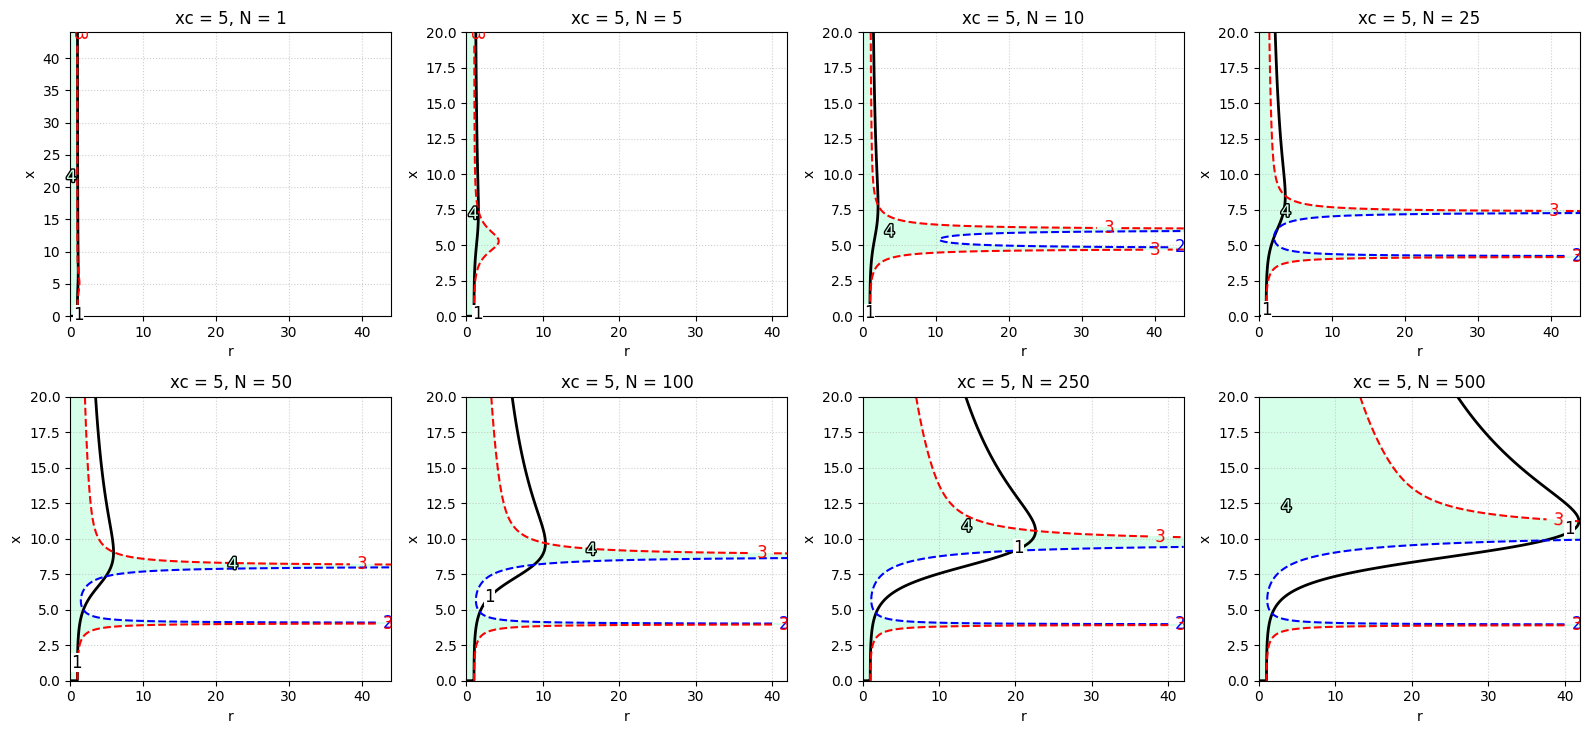

In [211]:
xc_values = [5]
N_values  = [1, 5, 10, 25, 50, 100, 250, 500]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 44, 5: 42, 25: 44, 0.5: 4, 10: 44, 50:44, 100: 42, 250: 42, 500: 42, 1000: 80}
ncols = 4

plot_stability(param_sets, x_max_map, r_max_map, ncols, 16, 8)

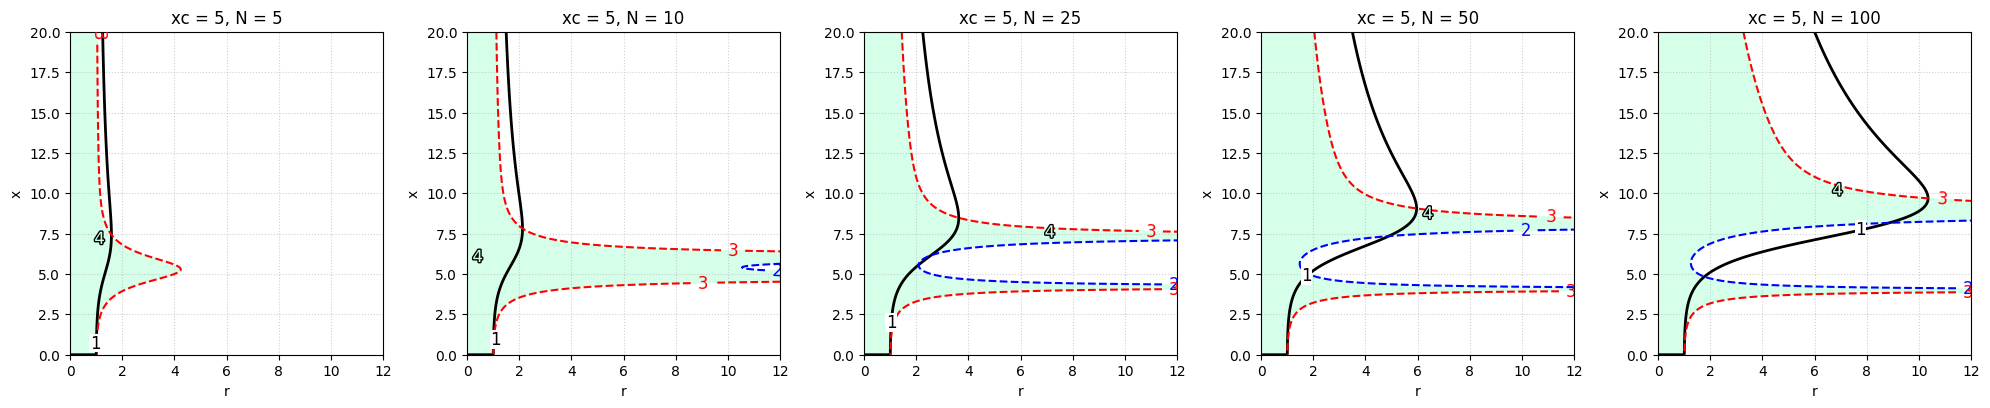

In [209]:
xc_values = [5]
N_values  = [5, 10, 25, 50, 100]

param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 44, 5: 20, 25: 20, 0.5: 10, 10: 20, 50: 20, 100: 20, 250: 20, 500: 20, 1000: 20}
r_max_map = {1: 12, 5: 12, 25: 12, 0.5: 4, 10: 12, 50:12, 100: 12, 250: 12, 500: 12, 1000: 80}
ncols = 5

plot_stability(param_sets, x_max_map, r_max_map, ncols, 20, 4.5)

D:\Temp\ipykernel_16176\3726264116.py:2: RuntimeWarning: overflow encountered in scalar multiply
  return r*x*(1 - 1/(1 + np.exp(xc - x))
D:\Temp\ipykernel_16176\3726264116.py:3: RuntimeWarning: invalid value encountered in scalar divide
  + x/((1 + np.exp(xc - x))*(N + x)))


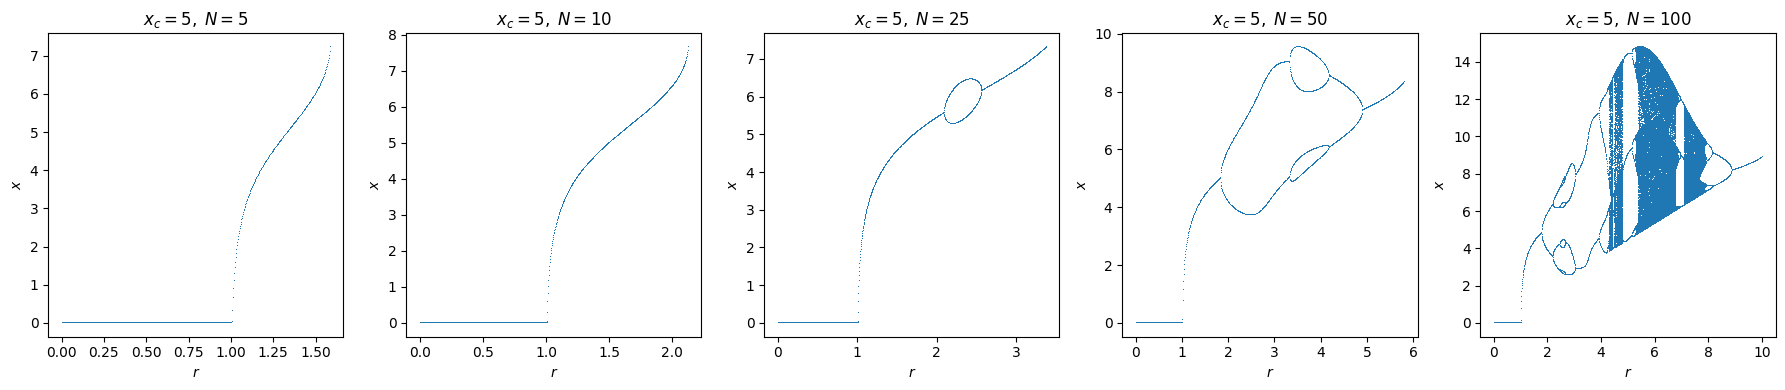

In [206]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

xc = 5
N_values  = [5, 10, 25, 50, 100]

for j, N in enumerate(N_values):
    r_bifurcation_ax(axes[j], xc, N, 4.5 if N < 50 else 10, 4 if N < 50 else 10)

plt.tight_layout()
plt.show()

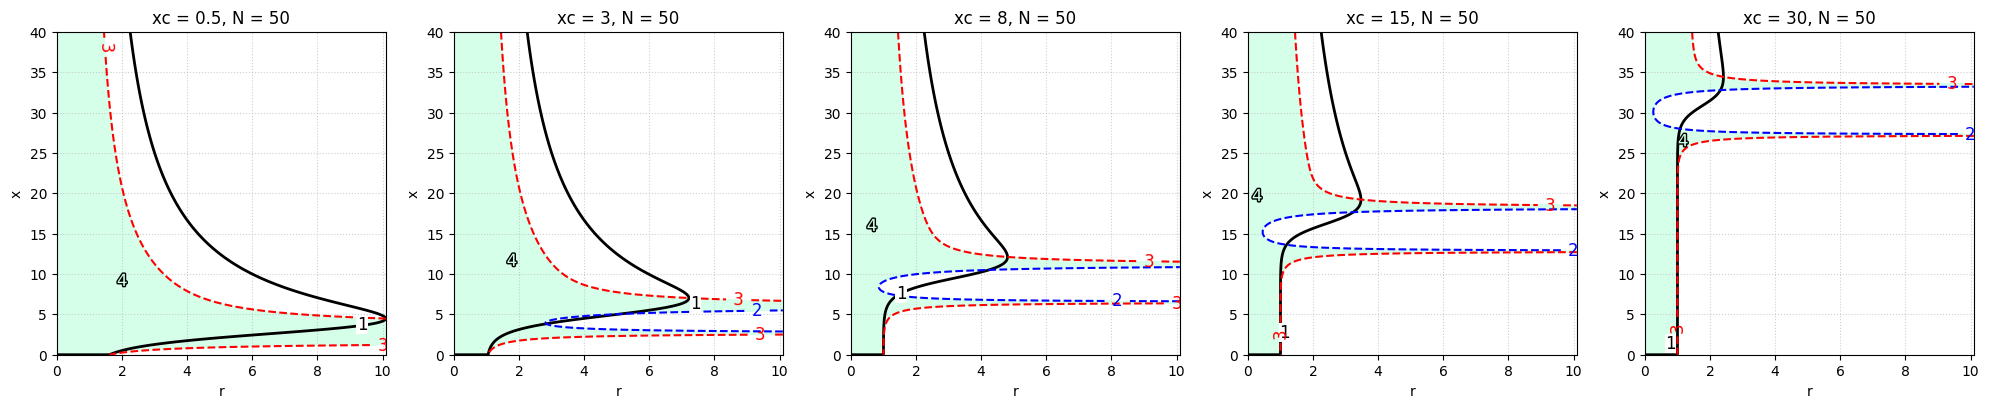

In [210]:
xc_values = [0.5, 3, 8, 15, 30]
N_values  = [50]
param_sets = [
    (y,x) for y in N_values for x in xc_values 
]

x_max_map = {1: 10, 25: 30, 0.5: 10, 10: 25, 50: 40, 100: 50, 250: 50, 500: 50, 1000: 50}
r_max_map = {1: 5, 25: 10, 0.5: 4, 10: 14, 50: 10.1, 100: 16, 250: 40, 500: 67, 1000: 150}
ncols = 5

plot_stability(param_sets, x_max_map, r_max_map, ncols, 20, 4.5)

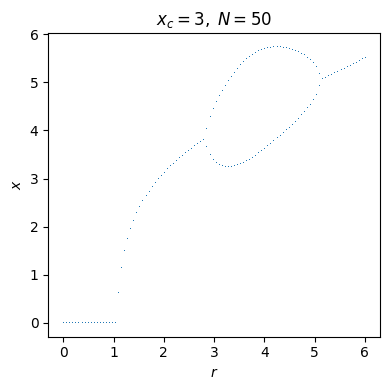

In [139]:
fig, axes = plt.subplots(1, 1, figsize=(4, 4))

N = 50
xc= 3

r_bifurcation_ax(axes, xc, N, 6, 6)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_16176\3726264116.py:2: RuntimeWarning: overflow encountered in scalar multiply
  return r*x*(1 - 1/(1 + np.exp(xc - x))
D:\Temp\ipykernel_16176\3726264116.py:3: RuntimeWarning: invalid value encountered in scalar divide
  + x/((1 + np.exp(xc - x))*(N + x)))


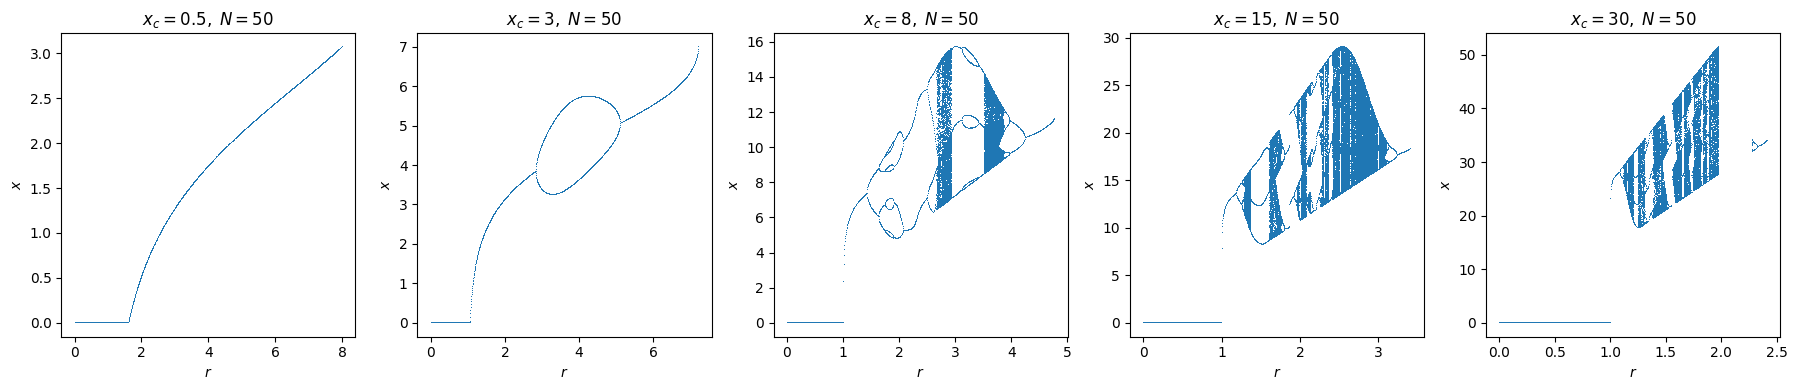

In [207]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

N = 50
xc_values  = [0.5, 3, 8, 15, 30]

for j, xc in enumerate(xc_values):
    r_bifurcation_ax(axes[j], xc, N, 6 if xc != 8 else 10, 8 if xc < 10 else 4)

plt.tight_layout()
plt.show()

# Рассмотрим случай N = 50, xc = 5 (рисунок [0,3]). r = 5.2, по графику при этом r существует 2 решения - подберем точки в окрестности этих решений и посмотрим их устойчивость


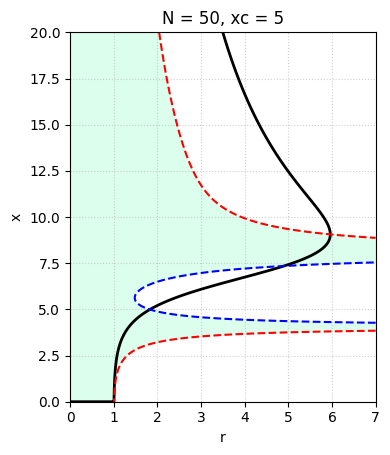

In [56]:
def draw_1xr(xc, N0, r_max, x_max):
    def F(x, r, N, xc):
        return r*x*(1 - 1/(1 + np.exp(xc - x))
                    + x/((1 + np.exp(xc - x))*(N + x)))
    
    def dF_dx(x, r, N, xc, h=1e-6):
        return (F(x+h, r, N, xc) - F(x-h, r, N, xc)) / (2*h)
    xc_values = [xc]
    N_values  = [N0]
    param_sets = [(y,x) for y in N_values for x in xc_values]
    fig, ax = plt.subplots(1, 1, figsize=(4, 5))
    
    for (N, xc) in param_sets:
        x = np.linspace(0, x_max, 1200)
        r = np.linspace(0, r_max, 1200)
        R, X = np.meshgrid(r, x)
    
        G = X - F(X, R, N, xc)
        dF = dF_dx(X, R, N, xc)
        stable = (dF > -1) & (dF < 1)
    
        ax.contourf(
            R, X, stable,
            levels=[0.5, 1],
            colors=['#ccffe5'],
            alpha=0.7
        )
        ax.contour(R, X, G, levels=[0], colors='black', linewidths=2)
        ax.contour(R, X, dF, levels=[-1], colors='blue', linestyles='dashed')
        ax.contour(R, X, dF, levels=[1], colors='red', linestyles='dashed')
    
        ax.set_title(f"N = {N}, xc = {xc}")
        ax.set_xlabel("r")
        ax.set_ylabel("x")
        ax.grid(True, linestyle=":", alpha=0.6)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()
draw_1xr(5, 50, 7, 20)

In [53]:
def f(x, xc):
    return 1.0 / (1.0 + np.exp(xc - x))
def m(x, N):
    return x / (N + x)
def Xn(x, r, N, xc = 5):
    F = f(x, xc)
    M = m(x, N)
    return (1 - F + F * M) * r * x

def r_tragectory(ax, xc_val, N_val, r_val, x0):
    N0 = N_val
    xc = xc_val
    r = r_val
    R = []
    X = []
    x = x0
    for n in range(125):
        x = Xn(x, r, N0, xc)
        R.append(n)
        X.append(x)
    ax.plot(R, X, ls='', marker='.')
    ax.set_title(f'x_c = {xc_val}, N = {N_val}, r= {r_val}, x_start = {x0}')
    ax.set_xlabel('$n$')
    ax.set_ylabel('$x_n$')

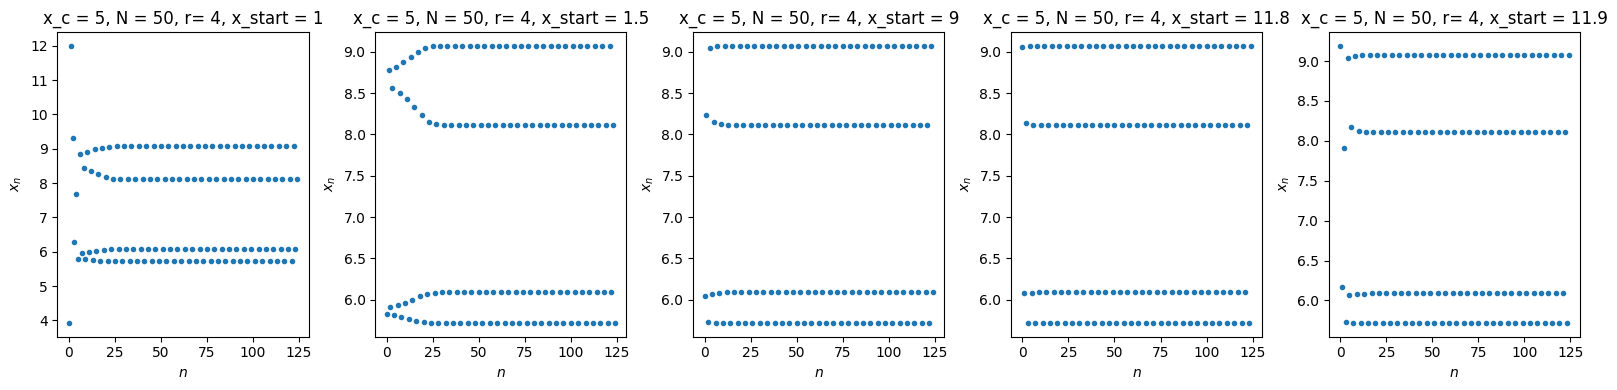

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 11.8, 11.9]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 5, 50, 4, x0)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_7092\2042315172.py:8: RuntimeWarning: overflow encountered in scalar multiply
  return (1 - F + F * M) * r * x
D:\Temp\ipykernel_7092\2042315172.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return x / (N + x)


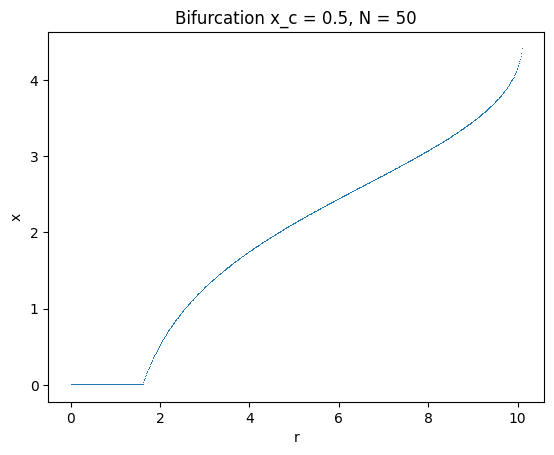

In [47]:
r_bifurcation(0.5, 50, 1, 12)

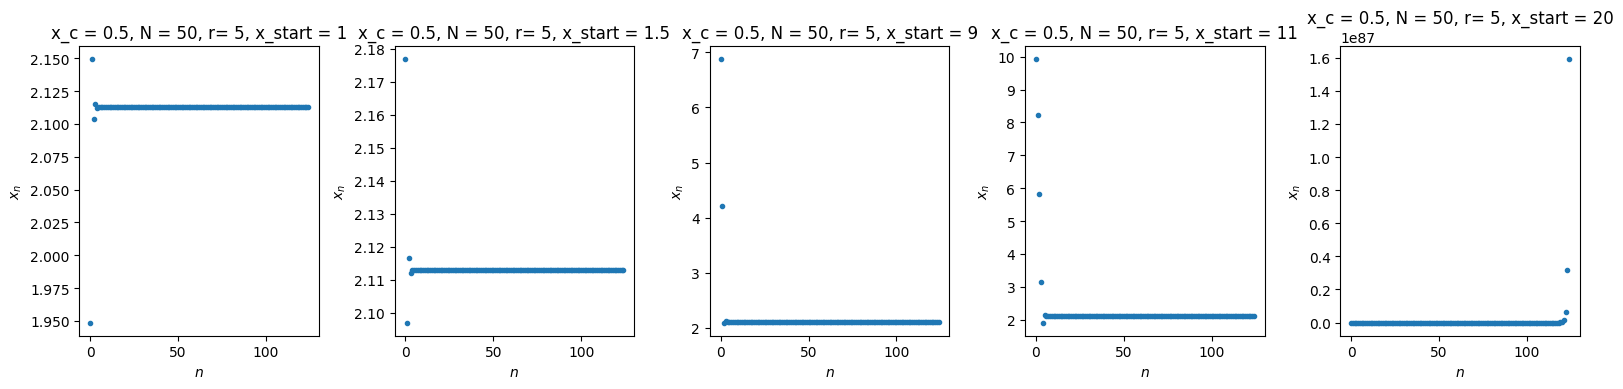

In [55]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 11, 20]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 0.5, 50, 5, x0)

plt.tight_layout()
plt.show()

D:\Temp\ipykernel_7092\2042315172.py:8: RuntimeWarning: overflow encountered in scalar multiply
  return (1 - F + F * M) * r * x
D:\Temp\ipykernel_7092\2042315172.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return x / (N + x)


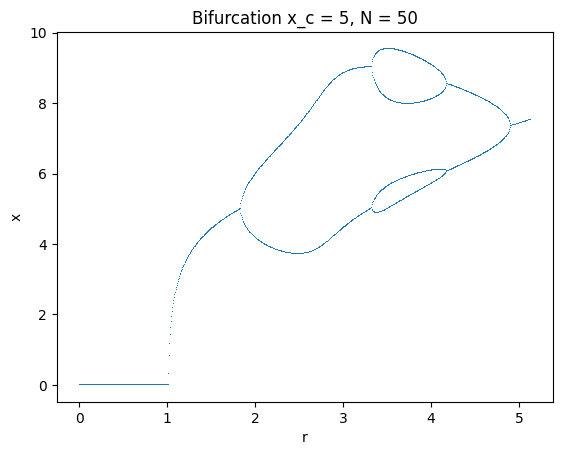

In [48]:
r_bifurcation(5, 50, 0.5, 6)

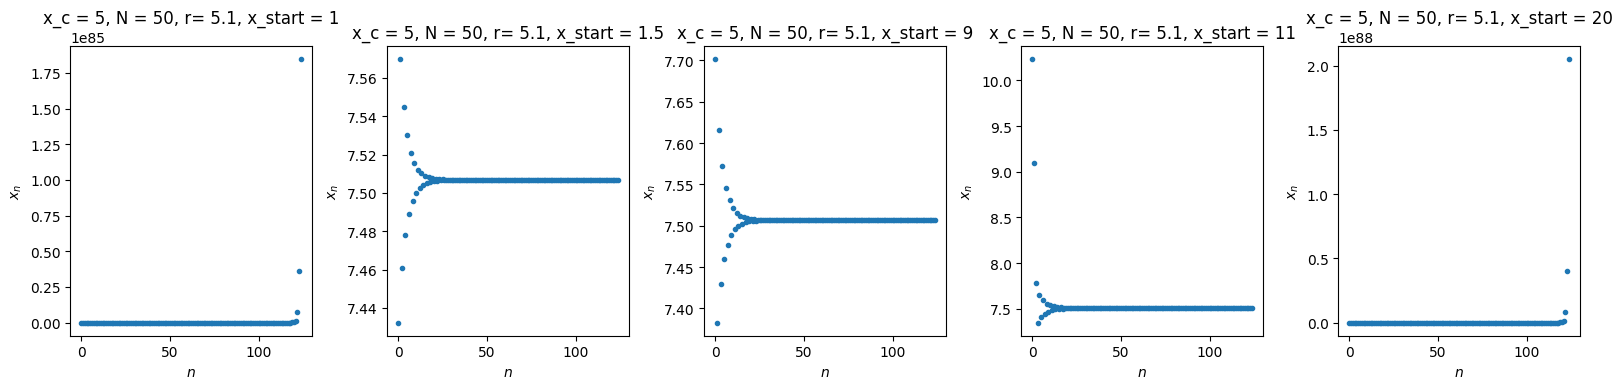

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
x0_values = [1, 1.5, 9, 11, 20]

for i, x0 in enumerate(x0_values):
    r_tragectory(axes[i], 5, 50, 5.1, x0)

plt.tight_layout()
plt.show()

# А вот случай N = 100, xc = 2.5 должен нормально и по бифуркациям и по графикам получиться


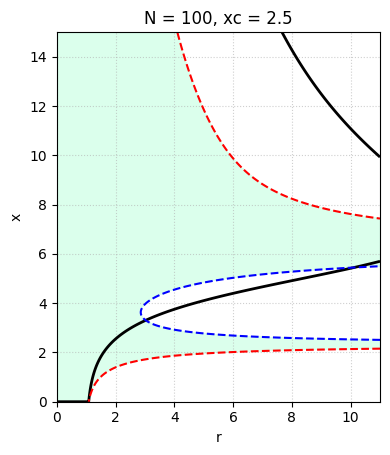

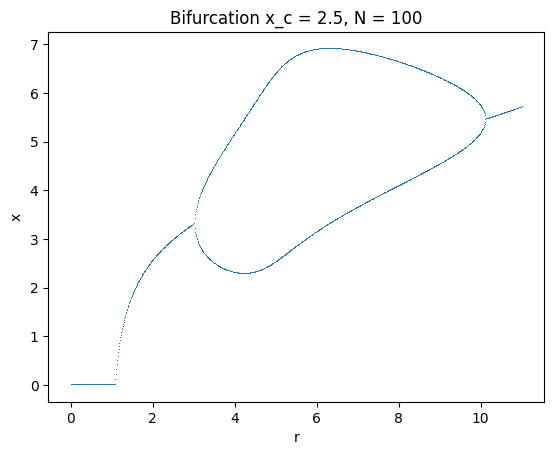

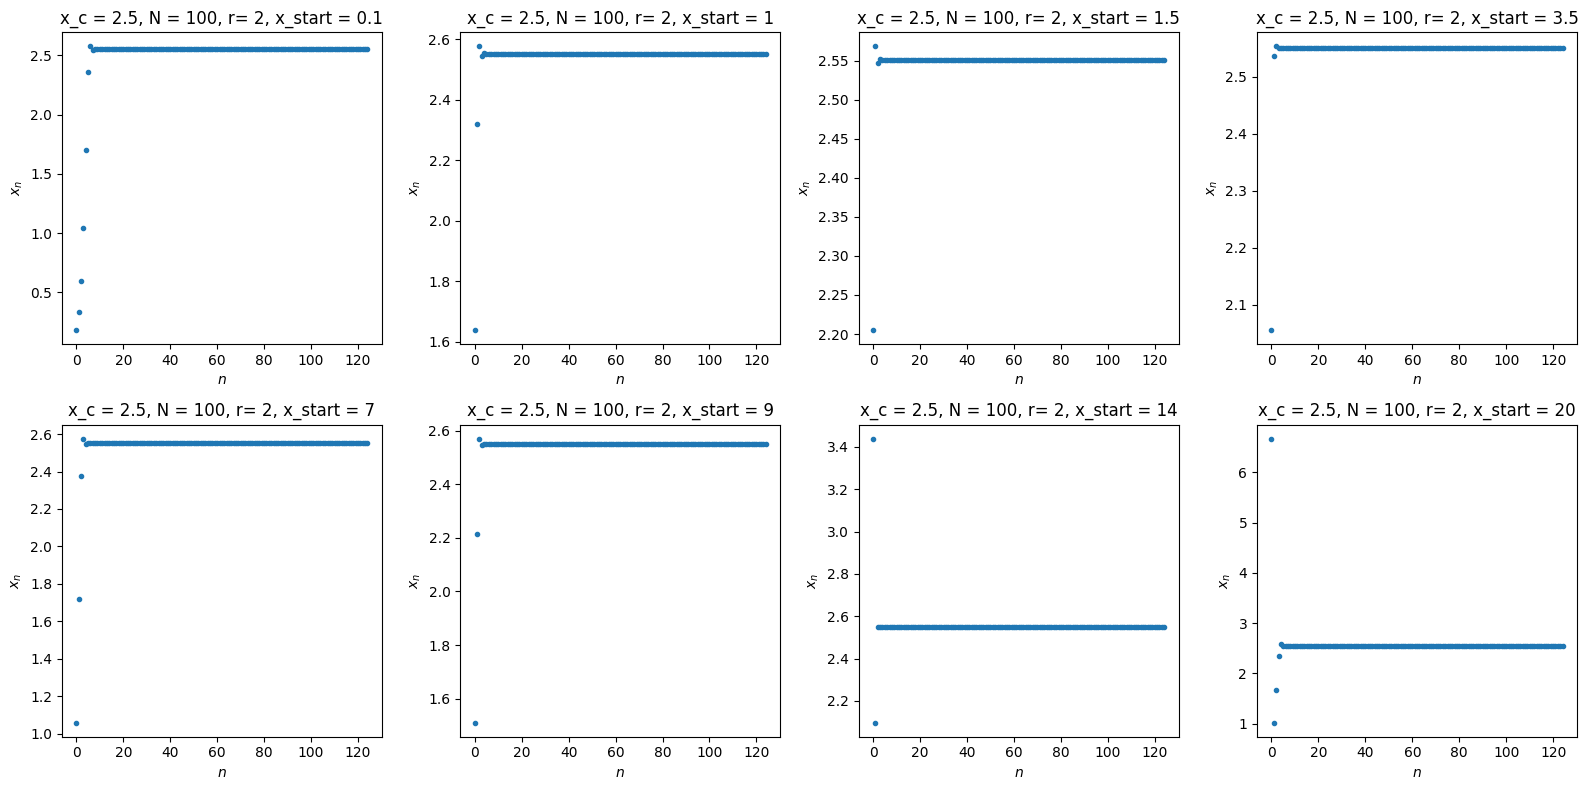

In [58]:
draw_1xr(xc=2.5, N0=100, r_max=11, x_max=15)
r_bifurcation(xc_val=2.5, N_val=100, x_start=1, r_max=11)

x0_values = [0.1, 1, 1.5, 3.5, 7, 9, 14, 20]
fig, axes = plt.subplots(2, len(x0_values) // 2, figsize=(16, 8))
for i, x0 in enumerate(x0_values[:len(x0_values) // 2]):
    r_tragectory(axes[0, i], 2.5, 100, 2, x0)
for i, x0 in enumerate(x0_values[len(x0_values) // 2:]):
    r_tragectory(axes[1, i], 2.5, 100, 2, x0)
plt.tight_layout()
plt.show()

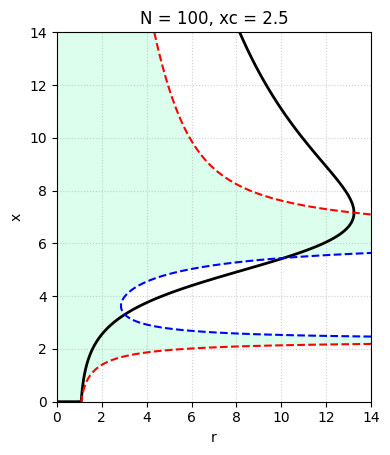

D:\Temp\ipykernel_7092\2042315172.py:8: RuntimeWarning: overflow encountered in scalar multiply
  return (1 - F + F * M) * r * x
D:\Temp\ipykernel_7092\2042315172.py:4: RuntimeWarning: invalid value encountered in scalar divide
  return x / (N + x)


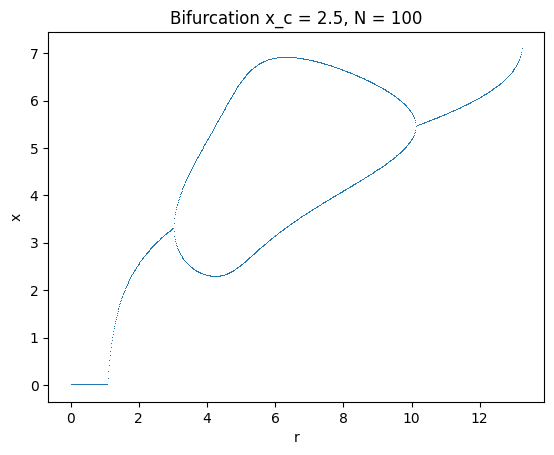

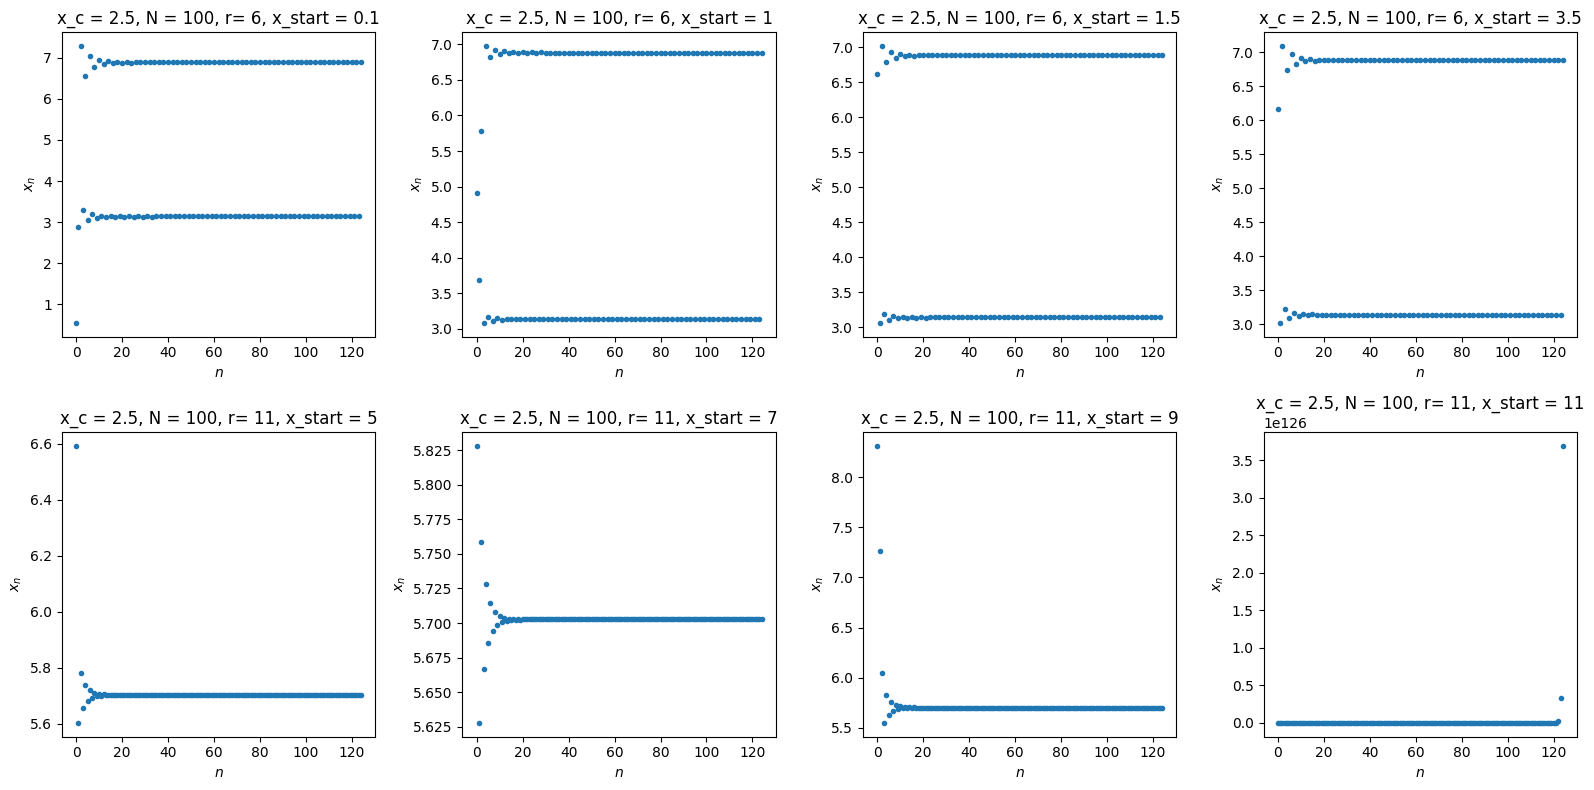

In [65]:
draw_1xr(xc=2.5, N0=100, r_max=14, x_max=14)
r_bifurcation(xc_val=2.5, N_val=100, x_start=0.5, r_max=14)

x0_values = [0.1, 1, 1.5, 3.5, 5, 7, 9, 11]
fig, axes = plt.subplots(2, len(x0_values) // 2, figsize=(16, 8))
for i, x0 in enumerate(x0_values[:len(x0_values) // 2]):
    r_tragectory(axes[0, i], 2.5, 100, 6, x0)
for i, x0 in enumerate(x0_values[len(x0_values) // 2:]):
    r_tragectory(axes[1, i], 2.5, 100, 11, x0)
plt.tight_layout()
plt.show()

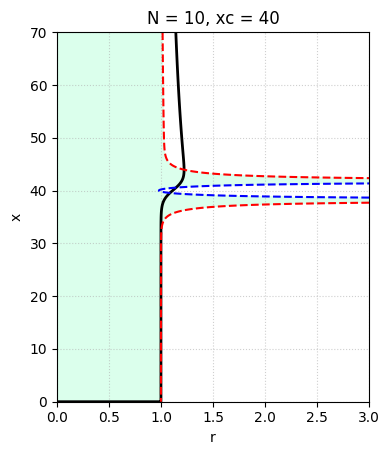

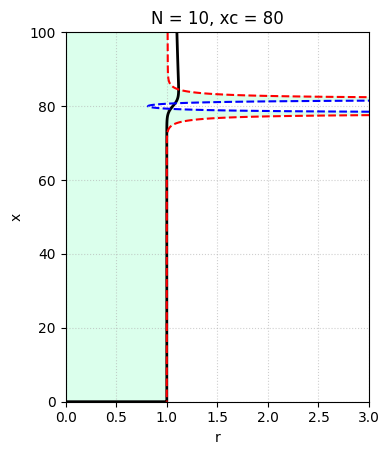

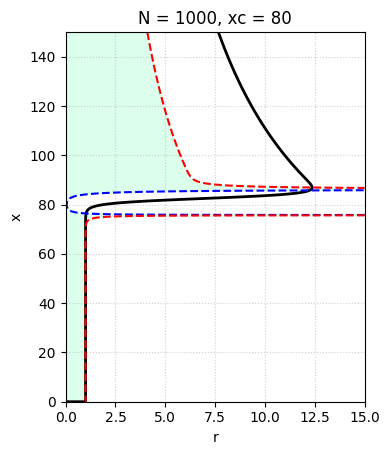

In [60]:
draw_1xr(40, 10, 3, 70)
draw_1xr(80, 10, 3, 100)
draw_1xr(80, 1000, 15, 150)

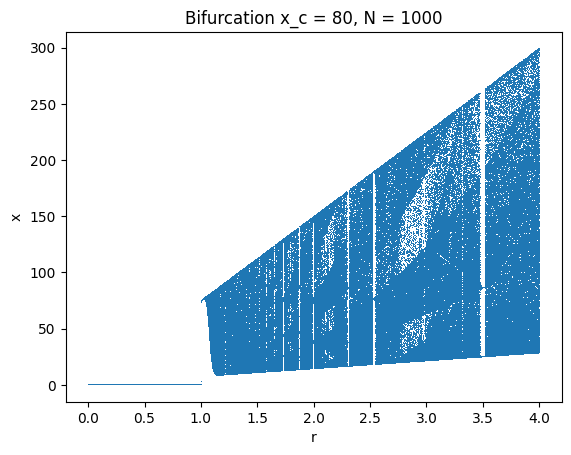

In [15]:
r_bifurcation(80, 1000, 1, 4)

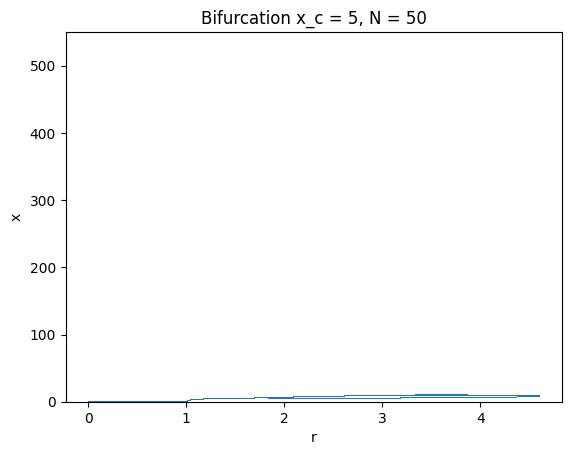

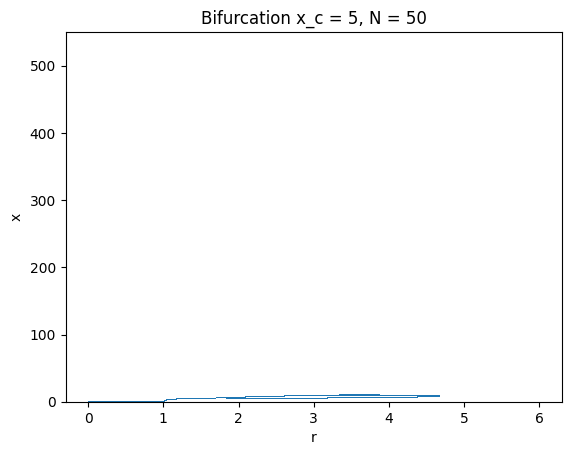

In [29]:
def r_bifurcation_lim(xc_val, N_val, x_start, r_max = 5):
    P = np.linspace(0, r_max, 5000)
    N0 = N_val
    xc = xc_val
    R = []
    X = []
    for r in P:
        x = x_start
        for n in range(225):
            x = Xn(x, r, N0, xc)
        for n in range(50):
            x = Xn(x, r, N0, xc)
            R.append(r)
            X.append(x)
    plt.plot(R, X, ls='', marker=',')
    plt.ylim(0,550)
    plt.title(f'Bifurcation x_c = {xc_val}, N = {N_val}')
    plt.xlabel('r')
    plt.ylabel('x')
    plt.show()
    
r_bifurcation_lim(5, 50, 1, 4.6)
r_bifurcation_lim(5, 50, 1, 6)